# Clasificación SVM con validación completa

Este notebook construye un dataset sintético reproducible para un problema binario, entrena un clasificador SVM y evalúa su rendimiento evitando fuga de información. El flujo incluye exploración, validación cruzada, selección de hiperparámetros, métricas de clasificación, curvas ROC y Precision-Recall, calibración de probabilidades y análisis de errores.

## Objetivos

1. Diseñar un dataset binario con variables numéricas interpretables y ruido controlado.
2. Separar los datos en entrenamiento, validación y prueba con estratificación.
3. Ajustar el escalado y el SVM únicamente dentro de un `Pipeline`.
4. Seleccionar `C` y `gamma` mediante validación cruzada estratificada y ROC-AUC.
5. Medir discriminación, clasificación, calibración y tipos de error sobre un test no usado durante el ajuste.

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibrationDisplay, calibration_curve
from sklearn.datasets import make_classification
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

## Curva Precision-Recall desde el Parquet de scores

El archivo debe estar en la misma carpeta que este notebook. Esta celda inspecciona el esquema y busca automáticamente una columna de etiqueta binaria y una columna numérica de score o probabilidad.

In [2]:
parquet_path = Path('part-00000-79ac8b3e-37c2-492c-bb64-d90f3e7d005a-c000.snappy.parquet')
if not parquet_path.exists():
    raise FileNotFoundError(
        f'No se encuentra {parquet_path.resolve()}. '
        'Copia el archivo Parquet en la carpeta del notebook.'
    )

scores_df = pd.read_parquet(parquet_path)
print(f'Filas: {len(scores_df):,}')
print('Columnas disponibles:')
display(pd.DataFrame({
    'column': scores_df.columns,
    'dtype': scores_df.dtypes.astype(str).values,
}))
display(scores_df.head())

# El Parquet usa TARGET_full como etiqueta y score como puntuación del modelo.
target_candidates = [
    column for column in scores_df.columns
    if column.lower() in {
        'target', 'target_full', 'label', 'y_true', 'actual', 'truth', 'class'
    }
]
score_candidates = [
    column for column in scores_df.columns
    if any(token in column.lower() for token in ['score', 'prob', 'probability', 'prediction'])
    and pd.api.types.is_numeric_dtype(scores_df[column])
]

if len(target_candidates) != 1 or len(score_candidates) != 1:
    raise ValueError(
        f'No se pudo identificar una única columna objetivo y score. '
        f'Objetivo detectado: {target_candidates}; score detectado: {score_candidates}. '
        'Define manualmente TARGET_COLUMN y SCORE_COLUMN.'
    )

TARGET_COLUMN = target_candidates[0]
SCORE_COLUMN = score_candidates[0]
y_scores = scores_df[TARGET_COLUMN].astype(int)
scores = scores_df[SCORE_COLUMN].astype(float)

if y_scores.nunique() < 2:
    raise ValueError(
        f'El Parquet no permite calcular Precision-Recall: {TARGET_COLUMN} '
        f'solo contiene la clase {y_scores.iloc[0]}. Se necesitan ejemplos de las clases 0 y 1.'
    )

print('Distribución de la etiqueta:')
display(y_scores.value_counts(normalize=True).sort_index().rename('proportion').to_frame())
print('Resumen del score por clase:')
display(scores_df.groupby(TARGET_COLUMN)[SCORE_COLUMN].agg(['count', 'min', 'mean', 'max']).round(4))

precision_parquet, recall_parquet, thresholds_parquet = precision_recall_curve(
    y_scores,
    scores,
)
ap_parquet = average_precision_score(y_scores, scores)

plt.figure(figsize=(7, 5))
plt.plot(recall_parquet, precision_parquet, label=f'AP = {ap_parquet:.3f}')
plt.axhline(
    y_scores.mean(),
    linestyle='--',
    color='gray',
    label=f'baseline = {y_scores.mean():.3f}',
)
plt.xlabel('Recall / Sensibilidad')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall desde el Parquet')
plt.legend()
plt.grid(True)
plt.show()

print(f'Columna objetivo: {TARGET_COLUMN}')
print(f'Columna score: {SCORE_COLUMN}')
print(f'Average Precision: {ap_parquet:.4f}')

Filas: 7,590
Columnas disponibles:


,column,dtype
0,TARGET_full,float64
1,asset_id,str
2,score,float64
3,year,int64
4,asset_name,str
5,component_name,str
6,component_id,str


,TARGET_full,asset_id,score,year,asset_name,component_name,component_id
0,0.0,1098741TIP001,0.311111,2025,energiaLacTrayectoestacionlacSustentador,full,energiaLacTrayectoestacionlacSustentador_10987...
1,0.0,1046468TIP001,0.311111,2025,energiaLacTrayectoestacionlacSustentador,full,energiaLacTrayectoestacionlacSustentador_10464...
2,0.0,107107944TIP001,0.311111,2025,energiaLacTrayectoestacionlacSustentador,full,energiaLacTrayectoestacionlacSustentador_10710...
3,0.0,107107727TIP001,0.311111,2025,energiaLacTrayectoestacionlacSustentador,full,energiaLacTrayectoestacionlacSustentador_10710...
4,0.0,107107153TIP006,0.311111,2025,energiaLacTrayectoestacionlacSustentador,full,energiaLacTrayectoestacionlacSustentador_10710...


ValueError: El Parquet no permite calcular Precision-Recall: TARGET_full solo contiene la clase 0. Se necesitan ejemplos de las clases 0 y 1.

## Diseño del dataset

Se generan 2.000 observaciones y seis variables numéricas:

- `signal_1`, `signal_2`: variables con mayor capacidad de separar las clases.
- `signal_3`, `signal_4`: variables auxiliares con correlación moderada.
- `noise_1`, `noise_2`: variables de ruido que dificultan la generalización.
- `target`: clase binaria equilibrada aproximadamente.

`make_classification` crea una distribución no trivial con clases parcialmente solapadas, redundancia y ruido.

In [4]:
feature_names = ['signal_1', 'signal_2', 'signal_3', 'signal_4', 'noise_1', 'noise_2']
X_array, y_array = make_classification(
    n_samples=2000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    class_sep=1.15,
    flip_y=0.06,
    weights=[0.55, 0.45],
    random_state=RANDOM_STATE,
)
df = pd.DataFrame(X_array, columns=feature_names)
df['target'] = y_array

print(f'Filas: {len(df):,}')
print(f'Variables predictoras: {len(feature_names)}')
print('Distribución de clases:')
display(df['target'].value_counts(normalize=True).rename('proportion').to_frame())
display(df.head())

Filas: 2,000
Variables predictoras: 6
Distribución de clases:


,proportion
target,
0,0.552
1,0.448


,signal_1,signal_2,signal_3,signal_4,noise_1,noise_2,target
0,1.908435,1.418554,2.470550,2.330881,-0.229699,-1.491008,1
1,0.047470,1.358006,-0.467800,-1.491335,-0.273642,0.828610,1
2,-0.383297,1.325385,-0.664036,-1.104524,0.499868,1.313054,0
3,-2.070662,-1.197675,-2.126081,-1.026129,-1.076858,2.339833,1
4,0.681323,0.972253,1.734700,2.885290,-2.070569,-1.098517,1


## Dataset adicional: clasificación binaria desbalanceada

Este segundo dataset contiene una clase positiva minoritaria. La proporción objetivo es aproximadamente 92% para la clase `0` y 8% para la clase `1`. En este escenario, `accuracy` puede ser engañosa, por lo que deben priorizarse `balanced_accuracy`, `precision`, `recall`, `F1`, `ROC-AUC` y `average_precision`.

In [2]:
imbalanced_feature_names = [
    'risk_signal_1', 'risk_signal_2', 'risk_signal_3',
    'context_1', 'noise_1', 'noise_2'
]

X_imbalanced_array, y_imbalanced_array = make_classification(
    n_samples=5000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    class_sep=1.0,
    flip_y=0.01,
    weights=[0.92, 0.08],
    random_state=RANDOM_STATE + 1,
)

df_imbalanced = pd.DataFrame(
    X_imbalanced_array,
    columns=imbalanced_feature_names,
)
df_imbalanced['target'] = y_imbalanced_array

X_imbalanced = df_imbalanced[imbalanced_feature_names]
y_imbalanced = df_imbalanced['target']

print(f'Filas: {len(df_imbalanced):,}')
print('Distribución absoluta de clases:')
display(y_imbalanced.value_counts().sort_index().rename('count').to_frame())
print('Distribución relativa de clases:')
display(y_imbalanced.value_counts(normalize=True).sort_index().rename('proportion').to_frame())
display(df_imbalanced.head())

Filas: 5,000
Distribución absoluta de clases:


,count
target,
0,4577
1,423


Distribución relativa de clases:


,proportion
target,
0,0.9154
1,0.0846


,risk_signal_1,risk_signal_2,risk_signal_3,context_1,noise_1,noise_2,target
0,-0.283923,-0.631211,2.167777,1.538724,0.409944,-0.332950,0
1,0.632951,0.179820,2.542705,3.543039,2.907610,1.956916,0
2,0.430600,0.596888,3.670263,2.674289,0.836921,0.656571,0
3,-0.952028,0.579804,-0.936125,0.835122,1.794639,-0.254659,0
4,-2.713507,0.095877,-0.948970,0.069074,0.136578,-1.989621,0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='signal_1', y='signal_2', hue='target', palette='Set1', alpha=0.65, ax=axes[0])
axes[0].set_title('Relación entre las dos señales principales')
sns.boxplot(data=df, x='target', y='signal_3', hue='target', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Distribución de signal_3 por clase')
plt.tight_layout()
plt.show()

display(df.groupby('target')[feature_names].mean().T.round(3))
display(df[feature_names].describe().T.round(3))

## Separación train / validación / test

Se reserva primero el 20% para test final. El 80% restante se divide en entrenamiento y validación. La estratificación mantiene la proporción de clases en cada subconjunto. El test se toca una sola vez al final.

In [5]:
X = df[feature_names]
y = df['target']
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid, test_size=0.25, stratify=y_train_valid, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    'rows': [len(y_train), len(y_valid), len(y_test)],
    'positive_rate': [y_train.mean(), y_valid.mean(), y_test.mean()],
}, index=['train', 'validation', 'test'])
display(split_summary.round(3))

,rows,positive_rate
train,1200,0.448
validation,400,0.448
test,400,0.448


## Pipeline SVM y selección de hiperparámetros

El escalado está dentro del pipeline, por lo que cada pliegue aprende sus medias y desviaciones solo con los datos de entrenamiento de ese pliegue. Así se evita fuga de información. `probability=True` permite obtener probabilidades para ROC, Precision-Recall y calibración.

In [6]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', probability=True, class_weight=None, random_state=RANDOM_STATE)),
])

param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
grid.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid.best_params_)
print(f'ROC-AUC medio CV: {grid.best_score_:.4f}')
cv_results = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
display(cv_results[['param_svm__C', 'param_svm__gamma', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(10).round(4))

Mejores hiperparámetros: {'svm__C': 10, 'svm__gamma': 0.1}
ROC-AUC medio CV: 0.9375


,param_svm__C,param_svm__gamma,mean_train_score,mean_test_score,std_test_score,rank_test_score
11,10.0,0.1,0.9545,0.9375,0.0114,1
8,10.0,scale,0.9644,0.9373,0.0128,2
4,1.0,scale,0.9470,0.9354,0.0078,3
15,100.0,0.1,0.9691,0.9332,0.0164,4
7,1.0,0.1,0.9398,0.9326,0.0081,5
12,100.0,scale,0.9791,0.9262,0.0168,6
14,100.0,0.01,0.9318,0.9250,0.0119,7
0,0.1,scale,0.9305,0.9241,0.0069,8
3,0.1,0.1,0.9207,0.9157,0.0077,9
10,10.0,0.01,0.9173,0.9124,0.0132,10


In [7]:
best_model = grid.best_estimator_
valid_pred = best_model.predict(X_valid)
valid_proba = best_model.predict_proba(X_valid)[:, 1]
validation_metrics = pd.Series({
    'accuracy': accuracy_score(y_valid, valid_pred),
    'balanced_accuracy': balanced_accuracy_score(y_valid, valid_pred),
    'precision': precision_score(y_valid, valid_pred, zero_division=0),
    'recall': recall_score(y_valid, valid_pred, zero_division=0),
    'f1': f1_score(y_valid, valid_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, valid_proba),
    'average_precision': average_precision_score(y_valid, valid_proba),
    'brier_score': brier_score_loss(y_valid, valid_proba),
}, name='validation')
display(validation_metrics.to_frame('value').round(4))

,value
accuracy,0.9150
balanced_accuracy,0.9098
precision,0.9448
recall,0.8603
f1,0.9006
roc_auc,0.9423
average_precision,0.9306
brier_score,0.0725


## Selección de umbral para SI fiables

La predicción por defecto usa umbral 0.50, pero no siempre es adecuada. Como el coste principal son los falsos positivos, seleccionamos en validación el umbral que logra al menos 90% de precision y conserva el mayor recall posible. El test no participa en esta decisión.

`MIN_PRECISION` debe ajustarse al nivel de fiabilidad requerido por el negocio.

In [8]:
MIN_PRECISION = 0.90
precision_values, recall_values, threshold_values = precision_recall_curve(y_valid, valid_proba)

# precision_recall_curve devuelve un punto adicional sin umbral.
threshold_table = pd.DataFrame({
    'threshold': threshold_values,
    'precision': precision_values[:-1],
    'recall': recall_values[:-1],
})

acceptable_thresholds = threshold_table[threshold_table['precision'] >= MIN_PRECISION]
if acceptable_thresholds.empty:
    raise ValueError('No se alcanzó la precision mínima; amplía el modelo o reduce MIN_PRECISION.')

selected_row = acceptable_thresholds.sort_values(
    ['recall', 'precision'], ascending=[False, False]
).iloc[0]
selected_threshold = float(selected_row['threshold'])
valid_pred_reliable = (valid_proba >= selected_threshold).astype(int)

threshold_metrics = pd.Series({
    'threshold': selected_threshold,
    'precision': precision_score(y_valid, valid_pred_reliable, zero_division=0),
    'recall': recall_score(y_valid, valid_pred_reliable, zero_division=0),
    'f1': f1_score(y_valid, valid_pred_reliable, zero_division=0),
}, name='validation_with_selected_threshold')
display(threshold_metrics.to_frame('value').round(4))

,value
threshold,0.4344
precision,0.9253
recall,0.8994
f1,0.9122


## Reajuste final y evaluación en test

Una vez seleccionados los hiperparámetros, se reajusta el pipeline con train + validation. El test permanece aislado hasta este momento.

In [9]:
final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf', probability=True, random_state=RANDOM_STATE,
        C=grid.best_params_['svm__C'], gamma=grid.best_params_['svm__gamma']
    )),
])
final_model.fit(X_train_valid, y_train_valid)
test_proba = final_model.predict_proba(X_test)[:, 1]

# Aplicar el umbral seleccionado únicamente con datos de validación.
test_pred = (test_proba >= selected_threshold).astype(int)

test_metrics = pd.Series({
    'accuracy': accuracy_score(y_test, test_pred),
    'balanced_accuracy': balanced_accuracy_score(y_test, test_pred),
    'precision': precision_score(y_test, test_pred, zero_division=0),
    'recall': recall_score(y_test, test_pred, zero_division=0),
    'f1': f1_score(y_test, test_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, test_proba),
    'average_precision': average_precision_score(y_test, test_proba),
    'brier_score': brier_score_loss(y_test, test_proba),
}, name='test')
display(test_metrics.to_frame('value').round(4))
print(f'Umbral aplicado para declarar SI: {selected_threshold:.4f}')
print(classification_report(y_test, test_pred, target_names=['class_0', 'class_1'], digits=4, zero_division=0))

,value
accuracy,0.8750
balanced_accuracy,0.8720
precision,0.8728
recall,0.8436
f1,0.8580
roc_auc,0.9202
average_precision,0.8825
brier_score,0.1000


Umbral aplicado para declarar SI: 0.4344
              precision    recall  f1-score   support

     class_0     0.8767    0.9005    0.8884       221
     class_1     0.8728    0.8436    0.8580       179

    accuracy                         0.8750       400
   macro avg     0.8747    0.8720    0.8732       400
weighted avg     0.8749    0.8750    0.8748       400



In [ ]:
cm = confusion_matrix(y_test, test_pred)
cm_norm = confusion_matrix(y_test, test_pred, normalize='true')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['class_0', 'class_1']).plot(cmap='Blues', ax=axes[0], values_format='d', colorbar=False)
axes[0].set_title('Matriz de confusión')
ConfusionMatrixDisplay(cm_norm, display_labels=['class_0', 'class_1']).plot(cmap='Blues', ax=axes[1], values_format='.2f', colorbar=False)
axes[1].set_title('Matriz normalizada por clase real')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
error_summary = pd.DataFrame({
    'count': [tn, fp, fn, tp],
    'meaning': ['true negatives', 'false positives', 'false negatives', 'true positives']
}, index=['TN', 'FP', 'FN', 'TP'])
display(error_summary)

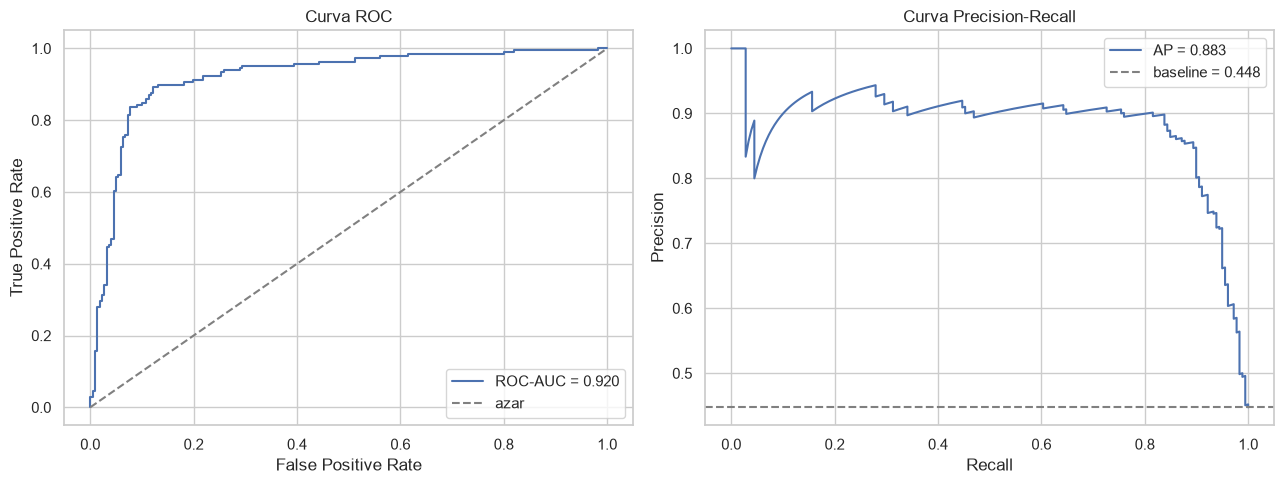

In [10]:
fpr, tpr, _ = roc_curve(y_test, test_proba)
precision, recall, _ = precision_recall_curve(y_test, test_proba)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'ROC-AUC = {test_metrics["roc_auc"]:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='azar')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='Curva ROC')
axes[0].legend()
axes[1].plot(recall, precision, label=f'AP = {test_metrics["average_precision"]:.3f}')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label=f'baseline = {y_test.mean():.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Curva Precision-Recall')
axes[1].legend()
plt.tight_layout()
plt.show()

## Calibración de probabilidades

El Brier score mide el error cuadrático de las probabilidades predichas: cuanto menor, mejor. La curva de calibración compara la probabilidad media predicha con la frecuencia observada de positivos por intervalo.

In [ ]:
prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(prob_pred, prob_true, marker='o', label='SVM')
ax.plot([0, 1], [0, 1], '--', color='gray', label='calibración perfecta')
ax.set(xlabel='Probabilidad media predicha', ylabel='Fracción positiva observada', title='Curva de calibración')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Brier score: {test_metrics["brier_score"]:.4f}')
print('Nota: SVC usa una calibración interna cuando probability=True; para producción conviene validarla en datos independientes.')

In [ ]:
test_results = X_test.copy()
test_results['actual'] = y_test
test_results['predicted'] = test_pred
test_results['probability_class_1'] = test_proba
test_results['error_type'] = np.select(
    [
        (test_results['actual'] == 0) & (test_results['predicted'] == 1),
        (test_results['actual'] == 1) & (test_results['predicted'] == 0),
    ],
    ['false_positive', 'false_negative'],
    default='correct'
)
display(test_results['error_type'].value_counts().to_frame('count'))

perm = permutation_importance(
    final_model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    'feature': feature_names,
    'mean_auc_decrease': perm.importances_mean,
    'std': perm.importances_std,
}).sort_values('mean_auc_decrease', ascending=False)
display(importance.round(4))

error_by_class = pd.crosstab(test_results['actual'], test_results['error_type'], normalize='index').round(3)
display(error_by_class)

In [ ]:
model_path = Path('svm_model.joblib')
joblib.dump({
    'model': final_model,
    'features': feature_names,
    'target': 'target',
    'random_state': RANDOM_STATE,
    'test_metrics': test_metrics.to_dict(),
}, model_path)
print(f'Modelo guardado en: {model_path.resolve()}')
loaded = joblib.load(model_path)
print('Revisión de carga:', loaded['model'].predict(X_test.head(3)).tolist())

## Conclusiones y criterios de validación

- `accuracy` resume aciertos globales, pero debe leerse junto con `balanced_accuracy` si las clases no están perfectamente equilibradas.
- `precision`, `recall` y `F1` muestran el comportamiento sobre la clase positiva; la métrica prioritaria depende del coste de falsos positivos y falsos negativos.
- `ROC-AUC` mide ordenamiento global y `average_precision` es especialmente útil cuando la clase positiva es menos frecuente.
- La matriz de confusión permite contar explícitamente `TN`, `FP`, `FN` y `TP`.
- El `Brier score` y la curva de calibración evalúan si las probabilidades son confiables, no solo si las etiquetas son correctas.
- La decisión final debe comparar las métricas de validación con las de test; una brecha grande puede indicar sobreajuste o cambio de distribución.

Para un uso real, sustituye el dataset sintético por datos de dominio, define una política de selección de umbral basada en costes y añade validación temporal o externa si las observaciones tienen dependencia temporal.